# **Семинар №6: множества**

*Над конспектом на разных итерациях курса работали: Тёма Стрельцов, Милена Камская, Вероника Царева*

**Множество** – это неупорядоченная изменяемая коллекция уникальных объектов неизменяемых типов данных (`str`, `int`, `float`, `tuple`, `bool`).

> Уникальные элементы = неповторяющиеся

Данные можно добавлять, удалять. У множеств можно искать (довольно быстро) объединения, пересечения и т.д. (чем-то напоминает математические множества).

А еще можно **быстро** проверить, есть ли какой-то элемент в множестве (для списков - **быстро** не получится).

Про «быстроту» = сложность функций вы будете говорить в рамках курса по математическому анализу на втором курсе, а пока просто будем запоминать некоторые факты (либо читать дополнительную литературу, см. конец тетрадки).

Собственно, операции с множествами работают «быстро», потому что множества – это один из примеров реализации хэш-таблицы (см. конец тетрадки). «Быстро» значит за константное время (т.е. не зависит от размера множества) – за $O(1)$.

### **Как создать множество?**

Пустое множество создается строго через `set()`.

In [8]:
s = {} # ВОТ ТАК ВОТ НЕ НАДО!
print(s, type(s))

{} <class 'dict'>


In [9]:
s = set() # НАДО ВОТ ТАК ВОТ!
print(s, type(s))

set() <class 'set'>


Непустое множество можно создать вручную через перечисление элементов в фигурных скобках, либо снова через функцию `set()` – в нее можно передать список или строку.

In [10]:
s = {1, 2, 3}
print(s)

{1, 2, 3}


In [11]:
s = set([1, 2, 3, 4, 5]) # так, удобно найти уникальные элементы
print(s)

{1, 2, 3, 4, 5}


Преобразовав список в множество, удобно найти уникальные элементы в коллекции.

In [12]:
list_with_repetitions = ['cat', 'dog', 'python', 'dino', 'snake', 'python']
set_without_repetitions = set(list_with_repetitions)
set_without_repetitions

{'cat', 'dino', 'dog', 'python', 'snake'}

### **«Скорость» выполнения операций**

Проверить, что какой-то элемент есть в множестве можно через `in`.

In [13]:
s = {1, 2, 3}
print(1 in s)
print(5 in s)

True
False


Замерим время работы метода `in` на списках и множествах.

In [14]:
# знакомьтесь, это компрехеншны – позволяют в одну строку создать вот так список и множество (и другие объекты тоже, но об этом – потом)

n = 10**4
my_list = [i ** 2 for i in range(n)]
my_set = {i ** 2 for i in range(n)}

In [15]:
%%timeit
# с помощью %%timeit можно изменить среднее время работы ячейки +- std
# если написать просто %%time будет результат одного запуска, без стандартного отклонения

for i in range(n):
    i in my_list  # можно никуда не присваивать, питон так тоже умеет

1.33 s ± 382 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [16]:
%%timeit
for i in range(n):
    i in my_set  # можно никуда не присваивать, питон так тоже умеет

575 µs ± 107 µs per loop (mean ± std. dev. of 7 runs, 1000 loops each)


## **Методы множеств**

Длина множества = количество элементов в нем

In [17]:
s = {1, 2, 3, 4}
print(s)

{1, 2, 3, 4}


Добавление элемента в множество

In [18]:
s = {1, 2, 3, 4}
s.add(5)
print(s)

{1, 2, 3, 4, 5}


Удаление элемента из множества

In [19]:
s.remove(5)
print(s)

{1, 2, 3, 4}


Удалить можно только то, что в множестве есть. Иначе – ошибка.

In [20]:
s.remove(-1)
print(s)

KeyError: -1

А вот так ошибки не будет!

In [21]:
s = {1, 2, 3, 4, 5}
s.discard(6) # не падает с ошибкой, если x нет в множестве
print(s)

{1, 2, 3, 4, 5}


Для множеств не доступна индексация, так как элементы там хранятся иначе (см. часть тетрадки про хеш-таблицу).

In [22]:
s = {1, 2, 3, 4, 5}
print(s[0]) # ошибка

TypeError: 'set' object is not subscriptable

Перебор элементов в множестве все равно осуществляется через цикл `for`.

In [33]:
s = {1, 2, 3, 4, 5}
for elem in s: # «проход по коллекции»
    print(elem)

1
2
3
4
5


In [34]:
print(*s) # красивый вывод

1 2 3 4 5


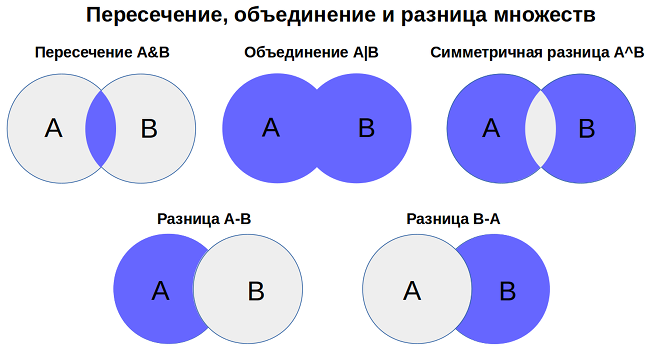

| Оператор | Метод | Значение |
|---|---|---|
| `A \| B` | `A.union(B)` | Возвращает объединение множеств A и B. |
| `A \|= B` | `A.update(B)` | Добавляет в A все элементы B. |
| `A & B` | `A.intersection(B)` | Возвращает пересечение множеств A и B. |
| `A &= B` | `A.intersection_update(B)` | Оставляет в A только элементы, которые есть в B. |
| `A - B` | `A.difference(B)` | Возвращает элементы A, не входящие в B. |
| `A -= B` | `A.difference_update(B)` | Удаляет из A все элементы, входящие в B. |
| `A ^ B` | `A.symmetric_difference(B)` | Возвращает элементы, входящие в A или B, но не в оба одновременно. |
| `A ^= B` | `A.symmetric_difference_update(B)` | Записывает в A симметрическую разность A и B. |
| `A <= B` | `A.issubset(B)` | Возвращает `True`, если A является подмножеством B. |
| `A >= B` | `A.issuperset(B)` | Возвращает `True`, если B является подмножеством A. |
| `A == B` | — | Множества A и B совпадают |
| `A != B` | — | Множества A и B не совпадают |
| `A < B` | — | Эквивалентно `A <= B and A != B`. |
| `A > B` | — | Эквивалентно `A >= B and A != B`. |

**NB!** Это верно только для тех случаев, когда обе переменных уже являются типом *set*.

Полный список команд можете посмотреть в [документации](https://python-reference.readthedocs.io/en/latest/docs/sets/).

Ниже – иллюстрация некоторых методов и/или операторов.

In [35]:
# проверка равенства и неравенство множеств
a = {1, 2, 3}
b = {1, 2, 3}
c = {1, 2, 4}

print(a == b)
print(b == c)
print(b != c)

True
False
True


In [36]:
a = {1, 2, 3}
b = {1, 2}
c = {1, 2, 3, 4}
print(b.issubset(a))
print(a.issubset(c))

# то же самое с <=
print(a <= b)

True
True
False


In [37]:
a = {1, 2, 3}
b = {1, 2, 3, 4}
с = {1, 2, 3, 4}
print(a < b)
print(b < c)

True
False


In [38]:
# пересечение множеств a и b
a = {1, 2}
b = {2, 3}
print(a & b) # a.intersection(b)

{2}


In [39]:
# объединение множеств a и b
a = {1, 2}
b = {2, 3}
print(a | b) # a.union(b)

{1, 2, 3}


In [40]:
# разность множеств a и b
a = {1, 2}
b = {2, 3}
print(a - b) # a.difference(b)

{1}


In [41]:
# симметрическая разность множеств а и b
a = {1, 2}
b = {2, 3}
print(a ^ b) # a.symmetric_difference(b)

{1, 3}


Ровно так же, как и списки, множества копируются по ссылке (изменяемые):

In [42]:
one_set = {1, 2, 3}
another_set = one_set
another_set.discard(2)

print(one_set)

{1, 3}


Поэтому нужно не забывать делать копии, если вам это нужно!

In [43]:
from copy import deepcopy

another_set = one_set.copy()
another_set = deepcopy(one_set)

**NB!** Положить во множества можно не абы что, а только неизменямые типы данных – по ним можно посчитать хеш (см. конец тетрадки).

In [44]:
s = {[1, 2, 3]}  # выдаст ошибку, список нельзя хешировать

TypeError: unhashable type: 'list'

In [45]:
s = {(1, 2, 3), (4, 5, 6, 7)}  # зато можно кортежи: почему?
print(s)

{(4, 5, 6, 7), (1, 2, 3)}


## **Практика**

Контест: https://contest.yandex.ru/contest/102587/problems/

Курс для подготовки к НЭ по программированию: https://edu.hse.ru/course/view.php?id=211219

Учебник: https://edu.hse.ru/course/view.php?id=133389


## **Дополнительно**

### **Как данные хранятся в множествах? Хеш-функции**

Что такое хеш-функция?

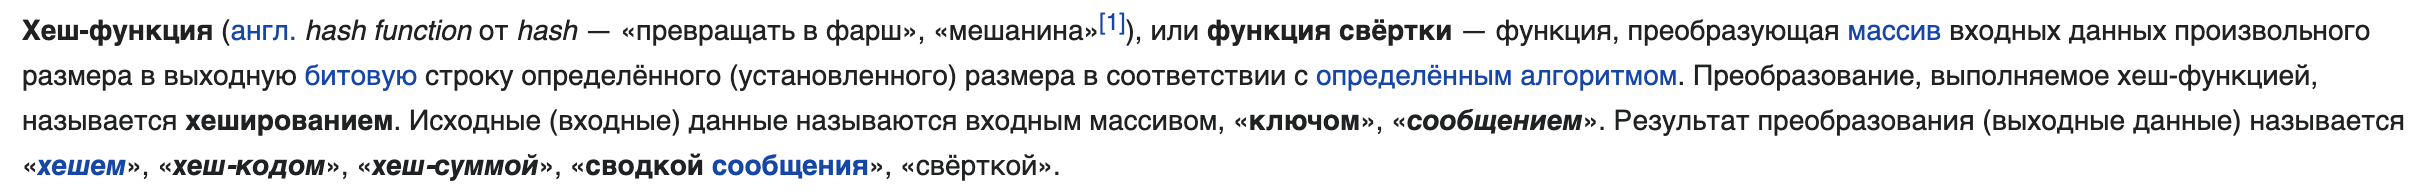

> **Definition:** A hash function is a function that takes a set of inputs of any arbitrary size and fits them into a table or other data structure that contains fixed-size elements.

Более просто (но это не общий случай), можно считать, что некоторый объект `obj` может быть передан некоторой функции $f$, такой что $f(obj) \in H\subset\mathbb{Z}$.

**Хэш** — это как «отпечаток пальца» для данных. Это число (или набор чисел), которое однозначно характеризует какой-то объект (строку, файл, изображение и т.д.).

**Простая аналогия:** представьте, что у вас есть книга. Хэш-функция — это все равно, что создать уникальный номер для этой книги по ее содержимому. Если взять другую книгу с точно таким же текстом — номер будет такой же. Если изменить хотя бы одну букву — номер изменится.

Хэш-функция `f` берет данные **любого размера** и выдает результат **фиксированного размера**.

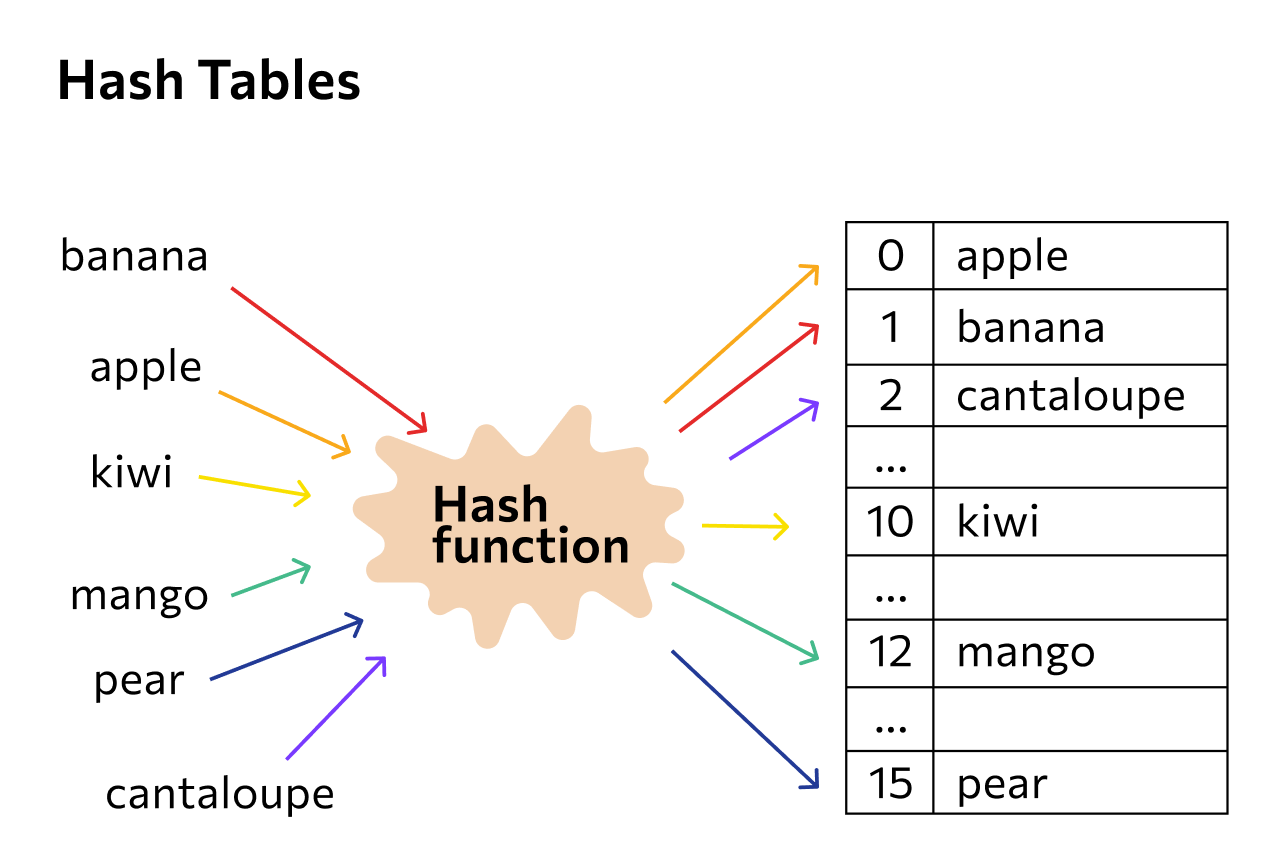

При желании мы сами можем придумать хеш-функцию и реализовать свою хеш-таблицу. Именно такая реализация позволяет быстро находить элементы в множестве (а не как в списке –– в худшем случае за его длину) –– мы перебираем не индексы, а считаем хеш.

Однако при этом могут быть коллизии.

**Коллизия** — это когда при применении одной функции к разным данным получается одинаковый хэш.

```
f("разные_данные_1") = f("разные_данные_2")
```

**Почему это происходит?**

Представьте, что у вас есть 1000 книг, но только 10 ящиков для хранения. По правилам (хэш-функции) вы распределяете книги по ящикам. Обязательно найдутся разные книги, которые попадут в один ящик — это и есть коллизия.

<img src="https://upload.wikimedia.org/wikipedia/commons/d/d0/Hash_table_5_0_1_1_1_1_1_LL.svg" style="background-color:white">

In [46]:
# простой пример хэш функции
# хэш-функция берет строку, суммирует ASCII-коды всех символов и берет остаток от деления на 10

key = input()
print(sum(ord(char) for char in key) % 10)

привет!!
2


Попробуйте поиграться с этим кодом и поперебирать строки – на каких входных данных вы получите коллизию (разные строки но один хеш)?

### **Другие структуры данных: дек**

Помимо встроенных структур данных (список, множество и т.д.) есть еще!

Например, дек – это структура данных, которая позволяет быстро добавлять элементы как в конец, так и в начало. На ее основе можно сделать очередь или двустороннюю очередь (это тоже особые структуры данных).

Все добавления и удаления из конца происходят за константное количество операций, то есть за $O(1)$. Это быстро и очень удобно. Удаление из любой другой части **не гарантируют** такую быстроту.

Прочитать подробнее про все это можно [здесь](https://contest.yandex.ru/tracks/algorithms/fundamental-data-structures/deque))

In [ ]:
from collections import deque  # deque потому что Double-Ended-QUEue

d = deque()

d.append("Vasya")
d.appendleft("Petya")
print('deque contains:', d)

print(d.popleft())
print('after popleft:', d)
print(d.pop())
print('after pop:', d)